<a href="https://colab.research.google.com/github/Yiting-Wang98/MSSP607/blob/main/Modules/week%2010/week%2010%20assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Year
2010    4.342104e+04
2011    7.075526e+06
2012    5.842485e+06
2013    1.635155e+07
2014    4.569472e+04
Name: SalesAmount, dtype: float64
Chart saved to: /content/MSSP607/data/week 7/week7_yearly_sales.pdf


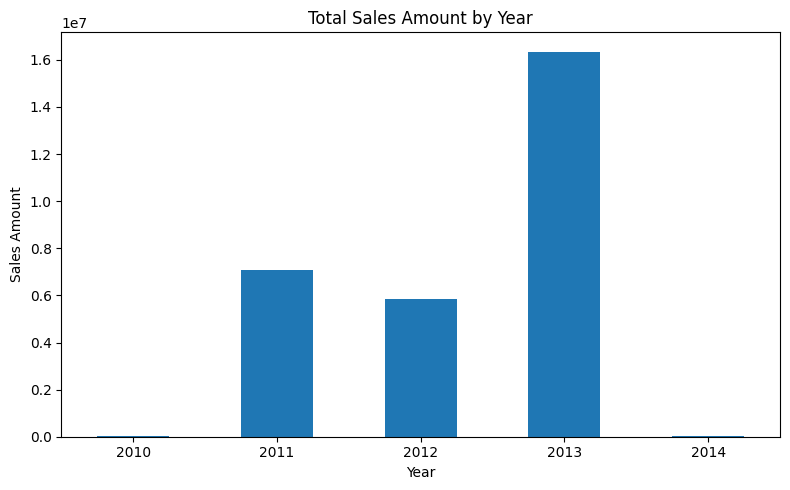

In [7]:
import subprocess
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from google.colab import userdata

# Read the GitHub token from Colab Secrets
github_token = userdata.get("Gitkey")

if not github_token:
    raise ValueError("Gitkey was not found. Add Gitkey to Colab Secrets.")

# GitHub repository information
owner = "Yiting-Wang98"
repository = "MSSP607"
clone_url = f"https://{github_token}@github.com/{owner}/{repository}.git"

# The repository will be cloned to /content/MSSP607
repo_path = Path("/content") / repository

# Clone the repository only if it has not already been cloned
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", clone_url],
        cwd="/content",
        check=True
    )

# Read the data using the path from your original notebook
data_path = repo_path / "data" / "week 7" / "InternetSales.csv"

if not data_path.exists():
    raise FileNotFoundError(f"Data file not found: {data_path}")

df = pd.read_csv(
    data_path,
    encoding="latin-1",
    low_memory=False
)

# Convert OrderDate to datetime format
df["OrderDate"] = pd.to_datetime(df["OrderDate"], errors="coerce")

# Remove rows with missing dates or sales amounts
df = df.dropna(subset=["OrderDate", "SalesAmount"]).copy()

# Extract the year from each order date
df["Year"] = df["OrderDate"].dt.year

# Calculate total sales for each year
yearly = df.groupby("Year")["SalesAmount"].sum().sort_index()

# Display total sales by year
print(yearly)

# Plot yearly sales totals
ax = yearly.plot(kind="bar", figsize=(8, 5))
ax.set_title("Total Sales Amount by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Sales Amount")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

# Save the chart before displaying it
output_path = repo_path / "data" / "week 7" / "week7_yearly_sales.pdf"
plt.savefig(output_path, bbox_inches="tight")
print(f"Chart saved to: {output_path}")

plt.show()